# Neuron Shapley values

The players are now the 128 neurons of `fc1`, with the same characteristic function: the negative mean cross-entropy loss on the validation images when only the neurons in $S$ are active. The notebook compares the pruning results with those of the channels, then studies a closed-form Shapley value, a cost per neuron to choose how many to keep, pruning both layers at once and robustness to input noise.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch

from shapley_pruning.data import Split, load_cifar10
from shapley_pruning.experiments import (fine_tuned_accuracies, masked_accuracies, rank_correlation,
                                         summarize, top_k_coalition_values)
from shapley_pruning.plots import REFERENCE, STYLES, plot_rules
from shapley_pruning.pruning import (count_parameters, l1_neuron_scores, prune_channels,
                                     prune_neurons, random_k, to_mask, top_k)
from shapley_pruning.shapley import (Game, channel_game, logit_shapley, neuron_game, percent_correct,
                                     permutation_shapley, true_class_logit)
from shapley_pruning.training import accuracy, add_noise, fine_tune, get_parent

In [2]:
data = load_cifar10()
parent = get_parent(data)
full_accuracy = accuracy(parent, data.test)
print(f"{count_parameters(parent):,} parameters, test accuracy {full_accuracy:.2f}%")

273,706 parameters, test accuracy 71.24%


## 1. Monte Carlo estimate

The estimator is the same as for the channels. An ordering of 128 neurons costs 129 evaluations, each of which only runs `fc2` on the cached `fc1` activations.

In [3]:
game = neuron_game(parent, data.val)
estimate = permutation_shapley(game, n_permutations=500)
phi, std_error = estimate.values, estimate.std_error

print(f"v(∅) = {estimate.empty_value:.4f}, v(N) = {estimate.full_value:.4f}")
print(f"Σ φ = {phi.sum():.4f},  v(N) − v(∅) = {estimate.full_value - estimate.empty_value:.4f}")
print(f"{(phi - 1.96 * std_error > 0).sum()} neurons with φ significantly above 0, "
      f"{(phi + 1.96 * std_error < 0).sum()} significantly below")

v(∅) = -2.3083, v(N) = -0.8922
Σ φ = 1.4161,  v(N) − v(∅) = 1.4161
59 neurons with φ significantly above 0, 2 significantly below


A neuron that never activates is a null player: adding it to a coalition never changes the output, so its Shapley value is 0. Such neurons matter for the comparisons below, because a random draw keeps them in proportion. The rule `Random active neurons` draws from the neurons that activate on at least one training image, and from the others only once all of those are kept, a fairer baseline.

In [4]:
with torch.no_grad():
    train_activations = torch.cat([parent.neuron_activations(parent.channel_activations(batch))
                                   for batch in data.train.images.split(1000)])
active = train_activations.amax(0) > 0
print(f"{(~active).sum()} of 128 neurons never activate on the training images, "
      f"largest |φ| among them: {phi[~active].abs().max():.1e}")

67 of 128 neurons never activate on the training images, largest |φ| among them: 0.0e+00


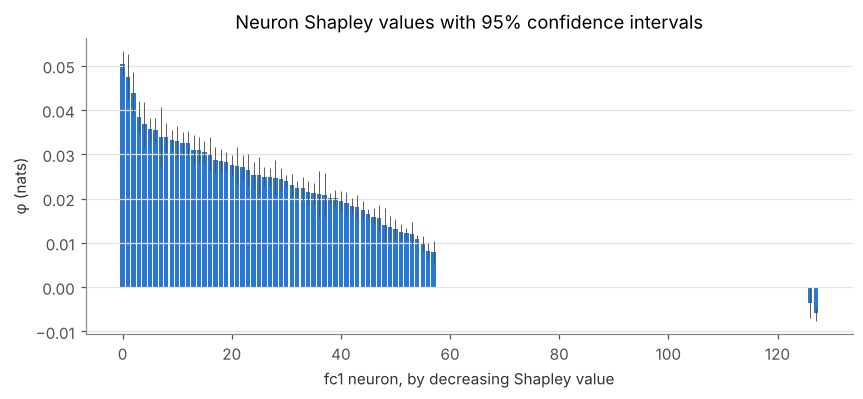

In [5]:
order = phi.argsort(descending=True)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(phi)), phi[order], color=STYLES["Shapley"][0], width=0.8)
ax.errorbar(range(len(phi)), phi[order], yerr=1.96 * std_error[order],
            fmt="none", ecolor="#52514e", elinewidth=0.6)
ax.set_xlabel("fc1 neuron, by decreasing Shapley value")
ax.set_ylabel("φ (nats)")
ax.set_title("Neuron Shapley values with 95% confidence intervals")
ax.grid(axis="x", visible=False)
fig.savefig("images/neuron_shapley_values.png")
plt.show()

59 neurons have a value significantly above 0 and 2 significantly below. The 67 neurons that never activate have a value of exactly 0, as the null-player axiom requires.

## 2. A closed form for the logit game

For the game whose payoff is the mean logit of the true class, $v_\text{logit}(S) = \frac{1}{|D_\text{val}|} \sum_{(x, y) \in D_\text{val}} z_y(x; m_S)$, the logit is affine in the masked activations:

$$z_y(x; m_S) = b_y + \sum_{i \in S} W_{y,i}\, a_i(x).$$

The marginal contribution of neuron $i$ is $W_{y,i}\, a_i(x)$ whatever the coalition, so its Shapley value is exactly $\phi_i^\text{logit} = \frac{1}{|D_\text{val}|} \sum_{(x, y) \in D_\text{val}} W_{y,i}\, a_i(x)$, one pass over the data with no sampling. It is the Shapley value of a different game: the loss is not affine in the activations, and raising the logit of the true class also helps when it is already far ahead. The check below compares it with a 20-ordering Monte Carlo estimate of the same game, then with the loss-based values.

In [6]:
phi_logit = logit_shapley(parent, data.val)
sampled = permutation_shapley(neuron_game(parent, data.val, payoff=true_class_logit), n_permutations=20)
print(f"largest difference from the Monte Carlo estimate: {(sampled.values - phi_logit).abs().max():.1e}")
print(f"rank correlation with the loss Shapley values over the active neurons: "
      f"{rank_correlation(phi_logit[active], phi[active]):.3f}")
print(f"top 32 in common: {len(set(top_k(phi_logit, 32).tolist()) & set(top_k(phi, 32).tolist()))}/32")

largest difference from the Monte Carlo estimate: 1.7e-07
rank correlation with the loss Shapley values over the active neurons: 0.483
top 32 in common: 23/32


The closed form matches the sampled values to float precision. Over the active neurons its ranking is only moderately correlated with that of the loss game, but the two share 23 of their top 32 neurons: they agree on which neurons matter most and differ on the order of the rest.

## 3. Accuracy of the rankings without retraining

The same comparison as for the channels, with the logit Shapley values and both random rules.

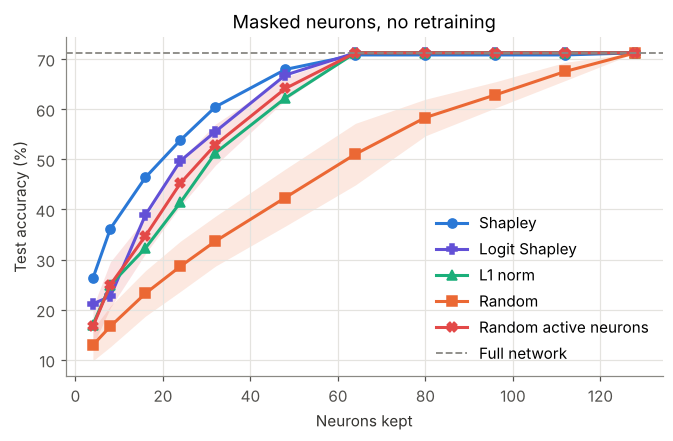

rule,Shapley,"Shapley, lowest first",Logit Shapley,L1 norm,Random,Random active neurons
k,,,,,,
8,36.19,4.68,22.67,24.98,16.69 ± 4.07,25.00 ± 4.57
16,46.39,4.68,38.91,32.29,23.25 ± 4.54,34.72 ± 3.55
32,60.46,4.68,55.54,51.27,33.67 ± 4.98,52.92 ± 4.10
64,70.82,4.68,71.24,71.24,51.03 ± 6.14,71.24 ± 0.00


In [7]:
test_game = neuron_game(parent, data.test, payoff=percent_correct)
rankings = {"Shapley": phi, "Shapley, lowest first": -phi,
            "Logit Shapley": phi_logit, "L1 norm": l1_neuron_scores(parent)}
random_pools = {"Random": None, "Random active neurons": active}
masked = masked_accuracies(test_game, rankings, sizes=[4, 8, 16, 24, 32, 48, 64, 80, 96, 112, 128],
                           random_pools=random_pools)

fig, ax = plt.subplots(figsize=(7, 4))
plot_rules(ax, masked[masked.rule != "Shapley, lowest first"], reference=full_accuracy)
ax.legend(loc="lower right")
ax.set_xlabel("Neurons kept")
ax.set_title("Masked neurons, no retraining")
fig.savefig("images/neuron_masked_accuracy.png")
plt.show()
summarize(masked[masked.k.isin([8, 16, 32, 64])])

The value of the top-$k$ coalition against its additive prediction $v(\varnothing) + \sum_{i \in S} \phi_i$, as for the channels:

In [8]:
top_k_coalition_values(game, estimate, sizes=[8, 16, 32, 64]).round(3)

,v(top k),v(∅) + Σ φ over the top k,"v(random k), mean"
k,,,
8,-1.801,-1.986,-2.194
16,-1.466,-1.728,-2.053
32,-1.147,-1.307,-1.833
64,-0.900,-0.883,-1.419


Without retraining, the neuron ranking works in this network, unlike the channel ranking. The top 8 Shapley values give 36.2% against 25.0 ± 4.6% for random active neurons, and the top 32 give 60.5% against 52.9 ± 4.1%. The logit Shapley values come second from 16 neurons on, and the L1 norm stays close to random active neurons. The lowest values give 4.7% at every size up to 64, since those coalitions hold the two neurons with negative values and neurons that never activate.

Here, the neuron game is close to additive: the top coalitions are within 0.3 nats of their additive prediction, slightly above it, and far above random coalitions. The neurons feed `fc2` directly, so the logits are affine in the coalition and only the softmax of the loss makes the neurons interact, whereas the channels pass through `fc1` and its ReLU.

## 4. Pruning and fine-tuning

`prune_neurons` removes the fc1 rows and biases of the dropped neurons and the fc2 columns that read them. The fine-tuning protocol is the one of the channel notebook: 3 epochs, Adam, learning rate $10^{-4}$, seeds 0, 1 and 2 for every rule.

In [9]:
keep = top_k(phi, 32)
pruned = prune_neurons(parent, keep)
images = data.test.images[:500]
difference = (pruned(images) - parent(images, neuron_mask=to_mask(keep, 128))).abs().max()
print(f"{count_parameters(pruned):,} parameters, largest output difference {difference:.1e}")

76,042 parameters, largest output difference 3.8e-06


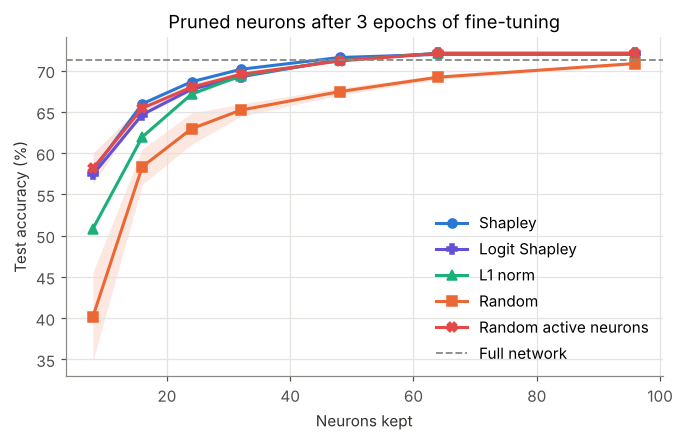

rule,Shapley,Logit Shapley,L1 norm,Random,Random active neurons
k,,,,,
8,57.89 ± 0.04,57.43 ± 0.19,50.85 ± 0.23,40.20 ± 5.36,58.15 ± 1.86
16,65.98 ± 0.15,64.67 ± 0.15,61.97 ± 0.23,58.35 ± 2.14,65.45 ± 0.39
24,68.66 ± 0.09,67.74 ± 0.20,67.16 ± 0.15,62.96 ± 1.91,67.99 ± 0.42
32,70.17 ± 0.11,69.27 ± 0.22,69.39 ± 0.18,65.22 ± 0.75,69.56 ± 0.37
48,71.60 ± 0.04,71.32 ± 0.09,71.26 ± 0.03,67.46 ± 0.43,71.17 ± 0.07
64,71.97 ± 0.13,72.10 ± 0.06,72.10 ± 0.06,69.21 ± 0.27,72.10 ± 0.06
96,71.97 ± 0.13,72.10 ± 0.06,72.10 ± 0.06,70.87 ± 0.19,72.10 ± 0.06


In [10]:
fine_tuned = fine_tuned_accuracies(
    parent, data, "neurons",
    {"Shapley": phi, "Logit Shapley": phi_logit, "L1 norm": l1_neuron_scores(parent)},
    sizes=[8, 16, 24, 32, 48, 64, 96], random_pools=random_pools)

fig, ax = plt.subplots(figsize=(7, 4))
plot_rules(ax, fine_tuned, reference=full_accuracy)
ax.set_xlabel("Neurons kept")
ax.set_title("Pruned neurons after 3 epochs of fine-tuning")
fig.savefig("images/neuron_fine_tuned_accuracy.png")
plt.show()
summarize(fine_tuned)

After fine-tuning, the Shapley selection is far ahead of plain random pruning, 17.7 points with 8 neurons, but most of that gap comes from the neurons that never activate. Random draws from the active neurons match it at 8 neurons, and from 16 to 48 neurons it keeps a small lead over them of 0.4 to 0.7 points, larger than their spread. From 64 neurons on, the rules that keep all 61 active neurons reach 72.1%, and the Shapley rule, which leaves out the two neurons with negative values, 72.0%; three more epochs of training put both above the parent. The logit Shapley values trail the loss-based ones by up to 1.3 points, and the L1 norm does worse than random active neurons up to 32 neurons.

## 5. A cost per neuron

Charging $\lambda$ per neuron kept gives the game $v_\lambda(S) = v(S) - \lambda |S|$. Every marginal contribution of the cost game $c(S) = |S|$ equals 1, so $\phi_i(c) = 1$, and by linearity of the Shapley value

$$\phi_i(v_\lambda) = \phi_i(v) - \lambda.$$

Keeping the neurons with a positive value, $S_\lambda = \{i : \phi_i(v) > \lambda\}$, keeps those whose average marginal contribution exceeds their cost. It is a threshold on the Shapley ranking: every $\lambda$ picks a top-$k$ set, so it chooses $k$ but does not search for the subset that maximises $v_\lambda$. The first cell checks the identity on the same orderings. The second places $S_\lambda$ for several values of $\lambda$ on the accuracy curve of the top-$k$ sets, without retraining.

In [11]:
lam = 0.005
penalised = Game(lambda mask: game.value(mask) - lam * mask.sum(), game.n_players)
shifted = permutation_shapley(penalised, n_permutations=20).values
unpenalised = permutation_shapley(game, n_permutations=20).values
print(f"largest |φ(v_λ) − (φ(v) − λ)|: {(shifted - (unpenalised - lam)).abs().max():.1e}")

largest |φ(v_λ) − (φ(v) − λ)|: 6.0e-08


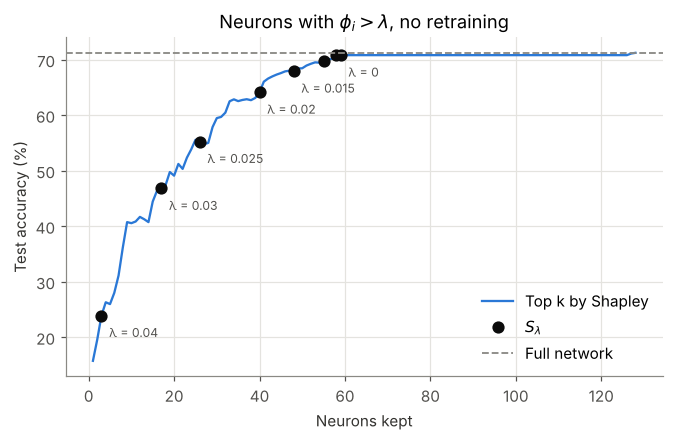

,λ,neurons kept,test accuracy (%)
0,0.000,59,70.820000
1,0.005,58,70.810005
2,0.010,55,69.770004
3,0.015,48,67.930000
4,0.020,40,64.139999
5,0.025,26,55.260002
6,0.030,17,46.799999
7,0.040,3,23.910000


In [12]:
top_k_curve = [test_game.value(to_mask(top_k(phi, k), 128)).item() for k in range(1, 129)]
rows = []
for lam in [0, 0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.04]:
    selected = (phi > lam).nonzero().flatten()
    rows.append({"λ": lam, "neurons kept": len(selected),
                 "test accuracy (%)": test_game.value(to_mask(selected, 128)).item()})
cost_sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 129), top_k_curve, color=STYLES["Shapley"][0], linewidth=1.5, label="Top k by Shapley")
ax.plot(cost_sweep["neurons kept"], cost_sweep["test accuracy (%)"], linestyle="none",
        marker="o", markersize=7, color="#0b0b0b", label="$S_\\lambda$")
last = None
for _, row in cost_sweep.iterrows():
    if last is None or abs(row["neurons kept"] - last) >= 6:
        ax.annotate(f"λ = {row['λ']:g}", (row["neurons kept"], row["test accuracy (%)"]),
                    textcoords="offset points", xytext=(5, -14), fontsize=8, color="#52514e")
        last = row["neurons kept"]
ax.axhline(full_accuracy, color=REFERENCE, linestyle="--", linewidth=1.2, label="Full network")
ax.set_xlabel("Neurons kept")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Neurons with $\\phi_i > \\lambda$, no retraining")
ax.legend()
fig.savefig("images/neuron_cost_sweep.png")
plt.show()
cost_sweep

Any $\lambda$ up to 0.005 keeps the 58 or 59 neurons with a positive value, nearly all the active ones, and costs 0.4 points without retraining. Larger values move down the top-$k$ curve: $\lambda = 0.02$ keeps 40 neurons at 64.1%, and $\lambda = 0.03$ keeps 17 at 46.8%. Every $S_\lambda$ lies on the curve, since it is a top-$k$ set.

## 6. Pruning channels and neurons together

The two layers are pruned to the same fraction of their units: $(k_\text{channels}, k_\text{neurons}) = (4, 16), (8, 32), (16, 64)$. The Shapley rule keeps the top channels, then estimates the neuron Shapley values of the network restricted to those channels, since removing channels changes what each neuron contributes. The random rules draw the channels at random, and the neurons either at random or from the active neurons first. Fine-tuning is unchanged.

In [13]:
channel_phi = permutation_shapley(channel_game(parent, data.val), n_permutations=500).values

rows = []
for n_channels, n_neurons in [(4, 16), (8, 32), (16, 64)]:
    channels = top_k(channel_phi, n_channels)
    conditional = neuron_game(parent, data.val, channel_mask=to_mask(channels, 32))
    neurons = top_k(permutation_shapley(conditional, n_permutations=200).values, n_neurons)
    for seed in (0, 1, 2):
        random_channels = random_k(32, n_channels, seed)
        selections = {"Shapley": (channels, neurons),
                      "Random": (random_channels, random_k(128, n_neurons, seed)),
                      "Random active neurons": (random_channels, random_k(128, n_neurons, seed, active))}
        for rule, (kept_channels, kept_neurons) in selections.items():
            model = prune_neurons(prune_channels(parent, kept_channels), kept_neurons)
            fine_tune(model, data.train, seed)
            rows.append({"rule": rule, "k": f"{n_channels} + {n_neurons}", "seed": seed,
                         "accuracy": accuracy(model, data.test)})
combined = pd.DataFrame(rows)
summarize(combined)

rule,Shapley,Random,Random active neurons
k,,,
4 + 16,42.69 ± 0.24,42.55 ± 1.05,44.21 ± 1.85
8 + 32,58.83 ± 0.11,53.41 ± 1.48,56.06 ± 0.88
16 + 64,66.30 ± 0.22,64.40 ± 1.42,66.85 ± 1.12


Here, pruning both layers gives no consistent gain. Against random channels with random active neurons, the Shapley rule is 2.8 points ahead with 8 channels and 32 neurons, and 1.5 and 0.6 points behind at the other two sizes, within the spread of the random draws. Plain random neurons do worse, again because of the neurons that never activate.

## 7. Robustness to Gaussian noise

Test images are corrupted with Gaussian noise of standard deviation $\sigma$ in pixel space, clipped to $[0, 1]$. Three selections of 32 neurons are compared, without retraining so that only the choice of neurons differs: the top 32 Shapley values on clean validation images, the top 32 on validation images with noise of $\sigma = 0.1$, and 20 random draws from the active neurons. The full network is the reference.

rank correlation between clean and noisy Shapley values over the active neurons: 0.170
top 32 in common: 20/32


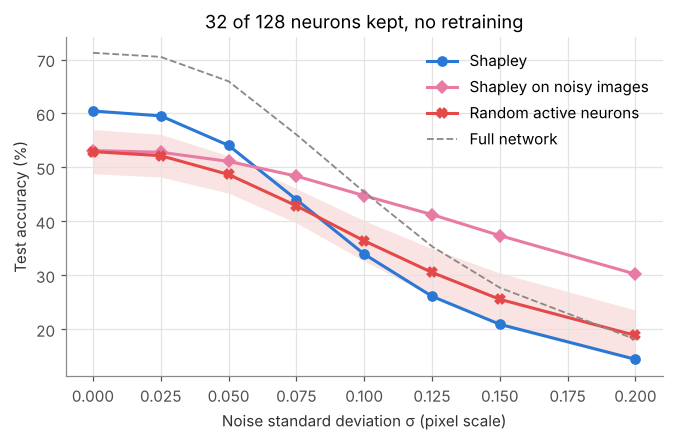

rule,Full network,Shapley,Shapley on noisy images,Random active neurons
noise_std,,,,
0.000,71.24,60.46,53.12,52.92 ± 4.10
0.025,70.49,59.55,52.81,52.18 ± 3.96
0.050,65.96,54.08,51.12,48.69 ± 3.46
0.075,56.09,44.04,48.39,42.89 ± 3.18
0.100,45.44,33.93,44.77,36.40 ± 3.73
0.125,35.36,26.11,41.26,30.54 ± 4.43
0.150,27.71,20.92,37.37,25.55 ± 4.88
0.200,18.13,14.43,30.23,18.86 ± 4.71


In [14]:
noisy_val = Split(add_noise(data.val.images, 0.1), data.val.labels)
phi_noisy = permutation_shapley(neuron_game(parent, noisy_val), n_permutations=500).values
print(f"rank correlation between clean and noisy Shapley values over the active neurons: "
      f"{rank_correlation(phi[active], phi_noisy[active]):.3f}")
print(f"top 32 in common: {len(set(top_k(phi, 32).tolist()) & set(top_k(phi_noisy, 32).tolist()))}/32")

rows = []
for noise_std in [0, 0.025, 0.05, 0.075, 0.1, 0.125, 0.15, 0.2]:
    noisy_test = Split(add_noise(data.test.images, noise_std), data.test.labels)
    noisy_game = neuron_game(parent, noisy_test, payoff=percent_correct)
    rows.append({"rule": "Full network", "noise_std": noise_std, "seed": 0,
                 "accuracy": noisy_game.value(torch.ones(128)).item()})
    for rule, scores in {"Shapley": phi, "Shapley on noisy images": phi_noisy}.items():
        rows.append({"rule": rule, "noise_std": noise_std, "seed": 0,
                     "accuracy": noisy_game.value(to_mask(top_k(scores, 32), 128)).item()})
    for seed in range(20):
        keep = random_k(128, 32, seed, active)
        rows.append({"rule": "Random active neurons", "noise_std": noise_std, "seed": seed,
                     "accuracy": noisy_game.value(to_mask(keep, 128)).item()})
robustness = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
plot_rules(ax, robustness[robustness.rule != "Full network"], x="noise_std")
full = robustness[robustness.rule == "Full network"]
ax.plot(full.noise_std, full.accuracy, color=REFERENCE, linestyle="--", linewidth=1.2,
        label="Full network")
ax.legend()
ax.set_xlabel("Noise standard deviation σ (pixel scale)")
ax.set_title("32 of 128 neurons kept, no retraining")
fig.savefig("images/neuron_noise_robustness.png")
plt.show()
summarize(robustness, by="noise_std")

The two selections differ: over the active neurons the clean and noisy values are only weakly correlated, and they share 20 of their top 32. Selected on clean images, the 32 neurons lose accuracy faster than random active neurons as the noise grows, and fall below them from $\sigma = 0.1$. Selected on noisy images, they start lower, 53.1% against 60.5% on clean images, but degrade slowly: they match the full network at $\sigma = 0.1$ and beat it beyond, 30.2% against 18.1% at $\sigma = 0.2$, without any retraining. The noisy values favour the neurons whose contribution survives the corruption, and the selection trades clean accuracy for robustness.